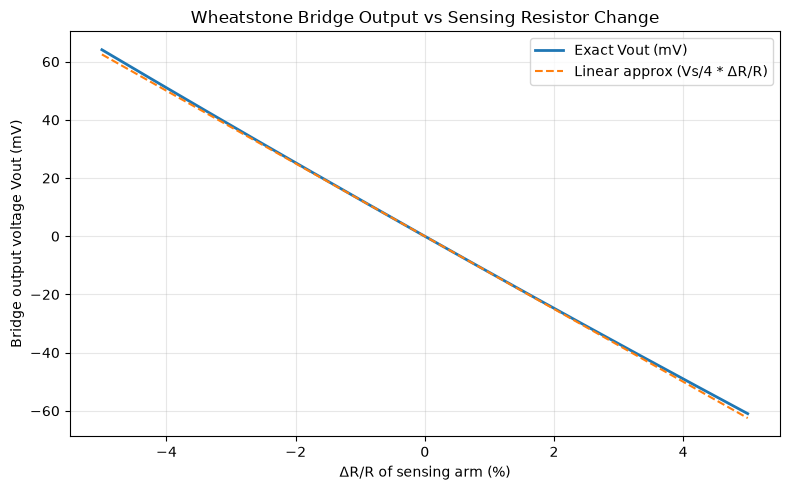

  ΔR/R (%) |     R3 (Ω) |    Vout exact (mV) |   Vout linear (mV)
-----------------------------------------------------------------
     -5.00 |     950.00 |            64.1026 |            62.5000
     -2.49 |     975.13 |            31.4845 |            31.0930
      0.03 |    1000.25 |            -0.3140 |            -0.3141
      2.54 |    1025.38 |           -31.3237 |           -31.7211
      5.00 |    1050.00 |           -60.9756 |           -62.5000

At balance (ΔR/R = 0): Vout = 0.0 V (as expected)


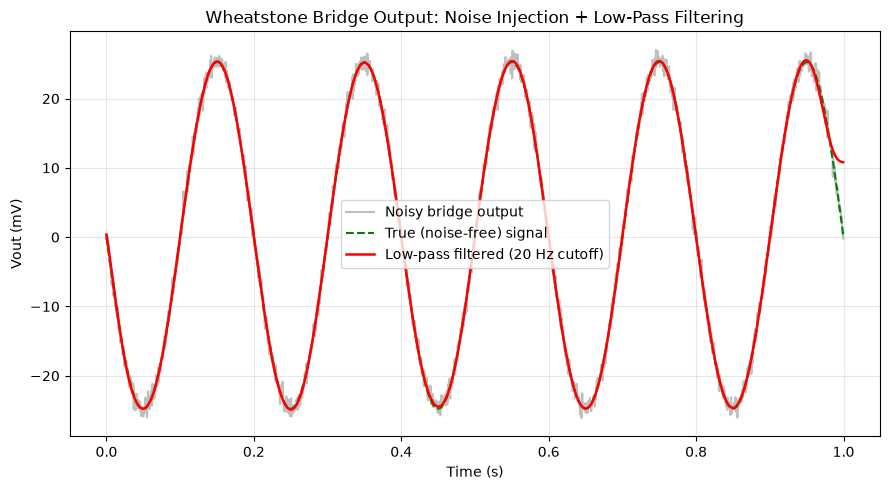


(Excluding 300 edge samples on each side to avoid filtfilt boundary transients)
RMS error (noisy vs clean):    0.7954 mV
RMS error (filtered vs clean): 0.1224 mV
Noise reduction factor:        6.50x


In [2]:
"""
Wheatstone Bridge Circuit Simulation
-------------------------------------
Simulates a Wheatstone bridge with one active arm (e.g., strain gauge / RTD)
and computes the output (differential) voltage as the sensing resistor
changes from its nominal value.

Bridge topology:
        Vs
        |
    R1 --- R2
    |         |
    A         B   -> Vout = V_A - V_B
    |         |
    R4 --- R3 (sensing element)
        |
       GND
"""

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Bridge parameters
# ---------------------------
Vs = 5.0          # Supply voltage (V)
R1 = 1000.0       # Ohms
R2 = 1000.0       # Ohms
R4 = 1000.0       # Ohms
R3_nominal = 1000.0  # Sensing element nominal resistance (balanced bridge)

def bridge_output(R1, R2, R3, R4, Vs):
    """
    Standard Wheatstone bridge output voltage.
    Node A is the junction of R1-R4, Node B is junction of R2-R3.
    """
    V_A = Vs * (R4 / (R1 + R4))
    V_B = Vs * (R3 / (R2 + R3))
    return V_A - V_B

# ---------------------------
# Sweep sensing resistor R3 over a fractional change (delta_R/R)
# ---------------------------
delta_R_over_R = np.linspace(-0.05, 0.05, 200)  # +/- 5% change (typical strain gauge range)
R3_values = R3_nominal * (1 + delta_R_over_R)

Vout = np.array([bridge_output(R1, R2, R3, R4, Vs) for R3 in R3_values])

# Linear approximation (small-signal, valid for small delta_R/R)
# Vout decreases as R3 increases (R3 is in the lower-right arm), hence the minus sign
Vout_linear_approx = -(Vs / 4) * delta_R_over_R

# ---------------------------
# Plot results
# ---------------------------
plt.figure(figsize=(8, 5))
plt.plot(delta_R_over_R * 100, Vout * 1000, label="Exact Vout (mV)", linewidth=2)
plt.plot(delta_R_over_R * 100, Vout_linear_approx * 1000, '--',
          label="Linear approx (Vs/4 * ΔR/R)", linewidth=1.5)
plt.xlabel("ΔR/R of sensing arm (%)")
plt.ylabel("Bridge output voltage Vout (mV)")
plt.title("Wheatstone Bridge Output vs Sensing Resistor Change")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------
# Print a few sample points
# ---------------------------
print(f"{'ΔR/R (%)':>10} | {'R3 (Ω)':>10} | {'Vout exact (mV)':>18} | {'Vout linear (mV)':>18}")
print("-" * 65)
for idx in [0, 50, 100, 150, 199]:
    print(f"{delta_R_over_R[idx]*100:10.2f} | {R3_values[idx]:10.2f} | "
          f"{Vout[idx]*1000:18.4f} | {Vout_linear_approx[idx]*1000:18.4f}")

print("\nAt balance (ΔR/R = 0): Vout =", round(bridge_output(R1, R2, R3_nominal, R4, Vs), 6), "V (as expected)")

# =============================================================
# Time-domain: noisy sensor signal + low-pass filtering
# =============================================================
from scipy.signal import butter, filtfilt

# --- Simulate a time-varying strain input (e.g., a vibrating structure) ---
fs = 2000.0                  # Sampling frequency (Hz)
T = 1.0                       # Total duration (s)
t = np.arange(0, T, 1 / fs)

signal_freq = 5.0             # Hz, the "true" mechanical signal of interest
strain_amplitude = 0.02       # ΔR/R amplitude (2%)
delta_R_over_R_t = strain_amplitude * np.sin(2 * np.pi * signal_freq * t)

R3_t = R3_nominal * (1 + delta_R_over_R_t)
Vout_clean = np.array([bridge_output(R1, R2, R3, R4, Vs) for R3 in R3_t])

# --- Inject sensor noise ---
np.random.seed(42)
noise_rms = 0.0008            # V, e.g. amplifier/thermal noise on the bridge output
noise = np.random.normal(0, noise_rms, size=Vout_clean.shape)
Vout_noisy = Vout_clean + noise

# --- Design a low-pass Butterworth filter ---
cutoff_freq = 20.0             # Hz, well above the 5 Hz signal, well below noise band
order = 4
nyquist = fs / 2
b, a = butter(order, cutoff_freq / nyquist, btype='low')
Vout_filtered = filtfilt(b, a, Vout_noisy)  # zero-phase filtering

# --- Plot time-domain results ---
plt.figure(figsize=(9, 5))
plt.plot(t, Vout_noisy * 1000, color='gray', alpha=0.5, label="Noisy bridge output")
plt.plot(t, Vout_clean * 1000, 'g--', linewidth=1.5, label="True (noise-free) signal")
plt.plot(t, Vout_filtered * 1000, 'r', linewidth=1.8, label=f"Low-pass filtered ({cutoff_freq:.0f} Hz cutoff)")
plt.xlabel("Time (s)")
plt.ylabel("Vout (mV)")
plt.title("Wheatstone Bridge Output: Noise Injection + Low-Pass Filtering")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- Quantify noise reduction ---
# NOTE: filtfilt (zero-phase filtering) distorts the first/last few filter
# time-constants of the signal ("edge effects" from padding/reflection at the
# boundaries). We exclude that transient region from the error metric, which
# is standard practice -- in a real-time system you'd see this same distortion
# every time the filter starts up.
edge_samples = int(0.15 * fs)  # ~150 ms settling region on each side
sl = slice(edge_samples, -edge_samples)

rmse_noisy = np.sqrt(np.mean((Vout_noisy[sl] - Vout_clean[sl]) ** 2))
rmse_filtered = np.sqrt(np.mean((Vout_filtered[sl] - Vout_clean[sl]) ** 2))
print(f"\n(Excluding {edge_samples} edge samples on each side to avoid filtfilt boundary transients)")
print(f"RMS error (noisy vs clean):    {rmse_noisy*1000:.4f} mV")
print(f"RMS error (filtered vs clean): {rmse_filtered*1000:.4f} mV")
print(f"Noise reduction factor:        {rmse_noisy/rmse_filtered:.2f}x")
